In [14]:
import sys
# sys.path.insert(0, '../../Utilities/')

from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad
from jax import random
from functools import partial
from jax.nn import relu, softplus

import matplotlib.pyplot as plt
import scipy.io
from scipy.interpolate import griddata

import time
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import mpmath

from Pwp_class import PiecewiseLinearPolynomials
from minmax_opt_class import pytree_l2_norm, MinMaxOptProb
from NN_class import MLP

# Generate key which is used to generate random numbers
key = random.PRNGKey(1)
 

In [15]:
# # exact solution
# nu = 4.84*10**-4
# c = 0.3
# ka = 1/2*np.sqrt(c/nu)
# om = c*ka
# x0 = 6
# def exact_sol(x, t):
#     return 3*c/np.cosh(ka*x-om*t-x0)**2
nu = 0.001

def u0(x):
    return -0.5*(jnp.sign(x) - 1)
def u_exact(t, x):
    return u0(x-0.5*t)

# def u0(x):
#     return -jnp.sign(x)
# def u_exact(t, x):
#     return u0(x)


# def u_exact(t, x):
#     # Initialize u as zero
#     u = 0.0
#     # Condition 1: x < 0, u = 0 (already zero by default)
#     # Condition 2: 0 < x < t and t > 0, u = x/t
#     u = jnp.where((x > 0) & (x < t) & (t > 0), x / t, u)
    
#     # Condition 3: t < x < 1 + t/2, u = 1
#     u = jnp.where((x > t) & (x < 1 + t / 2), 1.0, u)
    
#     # Condition 4: x > 1 + t/2, u = 0 (already zero by default)
#     return u
# vmap_u_exact = vmap(u_exact, in_axes=(0, 0), out_axes=0)

# def u0(x):
#     u = jnp.zeros_like(x)
#     u = jnp.where((x > 0) & (x < 1), 3.0, u)
#     return u

# Boundary at x=-1
def u1(x):
    # u = jnp.zeros_like(x)
    return jnp.ones_like(x)

# Boundary at x=1
def u2(x):
    # u = jnp.zeros_like(x)
    # return u
    return jnp.zeros_like(x)

def res_visc(u_quad, u_t, u_x, u_xx, nu):
    return u_t + u_quad * u_x - nu*u_xx
def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

t = np.linspace(0, 1, num = 101)
x = np.linspace(-1, 1, num = 201)
X, T = np.meshgrid(x, t)
layers_out = [2, 50, 50, 50, 50, 1]

Exact = u_exact(T, X)


# data = scipy.io.loadmat('/content/drive/My Drive/Colab Notebooks/KDV_IntConstra.mat');

# t = data['t'].flatten()[:,None]
# x = data['x'].flatten()[:,None]
# Exact = np.real(data['usol']).T

# t_size = len(t)
# X, T = np.meshgrid(x,t)

X_star = np.hstack((T.flatten()[:,None], X.flatten()[:,None]))
u_star = Exact.flatten()[:,None]

# Domain bounds
lb = X_star.min(0)
ub = X_star.max(0)

In [21]:
def initialize_NN(layers, key):
    params = []
    num_layers = len(layers)
    keys = random.split(key, len(layers))
    a = jnp.sqrt(0.01)
    params.append(a)
    for l in range(0, num_layers-1):
        W = xavier_init((layers[l], layers[l+1]), keys[l])
        b = jnp.zeros((layers[l+1],), dtype=np.float32)
        params.append((W,b))
    return params

def xavier_init(size, key):
    in_dim = size[0]
    out_dim = size[1]
    xavier_stddev = jnp.sqrt(2/(in_dim + out_dim))
    return random.truncated_normal(key, -2, 2, shape=(out_dim, in_dim), dtype=np.float32)*xavier_stddev

def net_u(params, X):
    X = jnp.concatenate([t,x])
    X = 2.0*(X - lb)/(ub - lb) - 1.0
    num_layers = len(params)
    a = params[0]
    for l in range(1, num_layers-1):
        W, b = params[l]
        X = jnp.tanh(10.0*a*jnp.dot(W, X) + b)
        # X = relu(10.0*a*jnp.dot(W, X) + b)
        # X = softplus(10.0*a*jnp.dot(W, X) + b)
    W, b = params_out[-1]
    Y = jnp.dot(W,X) + b
    Y = jnp.squeeze(Y)
    return Y

vmap_net_u = jit(vmap(net_u, in_axes=(None, 0, 0), out_axes=0))
net_u_t = jit(vmap(grad(net_u, 1), in_axes = (None, 0, 0), out_axes=0))
net_u_x = jit(vmap(grad(net_u, 2), in_axes = (None, 0, 0), out_axes=0))
net_u_xx = jit(vmap(grad(grad(net_u, 2),2), in_axes = (None, 0, 0), out_axes=0))
net_u_xxx = jit(vmap(grad(grad(grad(net_u, 2), 2), 2), in_axes = (None, 0, 0), out_axes=0))

def net_f(params_out, t, x, nu):
    u = vmap_net_u(params_out, t, x)
    u_t = net_u_t(params_out, t, x)
    u_x = net_u_x(params_out, t, x)
    u_xx = net_u_xx(params_out, t, x)
    u_xxx = net_u_xxx(params_out, t, x)
    f = u_t + u*u_x - nu*u_xx
    return f

def loss1(params, X, nu, u_bc, X_bc):
    u_pred_bc = vmap_net_u(params, X[:,0], X[:,1])
    l = jnp.mean(jnp.square(u_pred_bc-jnp.sin(X[:,0]+X[:,1])))
    return l

# Define Trapezoidal rule for vector f
def trap(f, n, a, b):
    h = (b - a) / (n-1)
    intgr = h*jnp.sum(f) - 0.5 * h * (f[0] + f[-1])
    # for i in range(1, n-1):
    #     intgr = intgr + h * f[i]
    return intgr

# Define Trapezoidal rule on axis=1
def trap1(f, n, a, b):
    h = (b - a) / (n-1)
    intgr = h*jnp.sum(f, axis=1) - 0.5 * h * (f[:,0] + f[:,-1])
    # for i in range(1, n-1):
    #     intgr = intgr + h * f[i]
    return intgr
vmap_trap = jit(vmap(trap, in_axes = (0, None, None, None), out_axes=0))

# @jit
# def get_invariants(params_out, params_int, nu, X_grid, X):
#     u = vmap_net_u(params_out, params_int, X_grid[:, 0], X_grid[:, 1])
#     u_x = net_u_x(params_out, params_int, X_grid[:, 0], X_grid[:, 1])
#     shape = X.shape
#     u = u.reshape(shape)
#     u_x = u_x.reshape(shape)
#     Invariant1 = trap1(u, shape[1], X[0,0], X[0,-1]) - 0.144598
#     Invariant2 = trap1(u**2, shape[1], X[0,0], X[0,-1]) - 0.086759
#     Invariant3 = vmap_trap(u**3 - 3*nu*u_x**2, shape[1], X[0,0], X[0,-1]) - 0.046852
#     return jnp.mean(jnp.square(Invariant1)) + jnp.mean(jnp.square(Invariant2)) + jnp.mean(jnp.square(Invariant3))

def lhs(d, N):
    return np.random.rand(N,d)

In [17]:
xx1 = np.hstack((T[0:1,:].T, X[0:1,:].T)) # (N_x,2) matrix, the initial condition points. Note t comes before x
# uu1 = Exact[0:1,:].T # (N_x, 1) matrix, the initial value
uu1 = u0(X[0:1,:].T)
xx2 = np.hstack((T[:,0:1], X[:,0:1])) # (N_t,2) matrix, the left bounary points
uu2 = u1(X[:,0:1]) # (N_t,1) matrix, the left bounary values
xx3 = np.hstack((T[:,-1:], X[:,-1:])) # (N_t,2) matrix, the right bounary points
uu3 = u2(X[:,-1:]) # (N_t,1) matrix, the right bounary values

# X_bc is the boundary and initial data sample, with u_bc as the function value
# X_f_train is the random points + X_bc

X_bc = np.vstack([xx1, xx2, xx3])
u_bc = np.vstack([uu1, uu2, uu3])
# X_f_train = lb + (ub-lb)*lhs(2, N_f)
# X_f_train = np.vstack((X_f_train, X_bc))
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=0.01,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=1, x_min=-1, x_max=1,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
)
quad_points = optProb.pwp.quad_points
quad_weights = optProb.pwp.quad_weights
X_f_train = quad_points


# make the order of X_bc and u_bc to be random
# idx = np.random.choice(X_bc.shape[0], N_u, replace=False)
# X_bc = X_bc[idx, :]
# u_bc = u_bc[idx, :]
#u_bc = u_bc.reshape((u_bc.size,))

params_out = initialize_NN(layers_out, key)
# params_int = initialize_NN_extra(layers_int, key)
opt_init, opt_update, get_params = optimizers.adam(step_size=0.0002)
opt_state_out = opt_init(params_out)

def loss(params_out, X_train, nu, u_bc, X_bc, X_grid, X):
    u_pred_bc = vmap_net_u(params_out, X_bc[:,0], X_bc[:,1])
    # Invariants = get_invariants(params_out, nu, X_grid, X)
    res = net_f(params_out, X_train[:,0], X_train[:,1], nu)
    loss_int = jnp.dot(res**2, quad_weights)
    l = 50*jnp.mean(jnp.square(u_pred_bc-u_bc)) + loss_int
    return l

In [20]:
type(get_params(opt_state_out))

list

In [11]:
import time

@jit
def step_out(i, opt_state_out, X_train, nu, u_bc, X_bc, X_grid, X):
    params_out = get_params(opt_state_out)
    val, g = value_and_grad(loss)(params_out, X_train, nu, u_bc, X_bc, X_grid, X)
    return val, opt_update(i, g, opt_state_out)

start_time = time.perf_counter()
loss_val_his = []
# inv_val_his = []
for i in range(10001):
    loss_val, opt_state_out = step_out(i, opt_state_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    # inv_val = get_invariants(params_out, params_int, nu, X_star, X)
    # loss_val = loss(params_out, X_f_train, nu, u_bc[:,0], X_bc, X_star, X)
    loss_val_his.append(loss_val)
    # inv_val_his.append(inv_val)
    if i % 200 == 0:
        #elapsed = time.time() - start_time
        # params_out = get_params(opt_state_out)
        # a_value = params_out[0]
        print('It: %d, Loss: %.3e' % (i, loss_val))
params_out = get_params(opt_state_out)
loss_val_his = jnp.array(loss_val_his)
# inv_val_his = jnp.array(inv_val_his)
end_time = time.perf_counter()
train_total_time = (end_time - start_time)
print(f"Train total time: {train_total_time:.8f} seconds")

It: 0, Loss: 2.246e+01
It: 200, Loss: 1.795e+00
It: 400, Loss: 8.551e-01
It: 600, Loss: 5.901e-01
It: 800, Loss: 4.379e-01
It: 1000, Loss: 3.550e-01
It: 1200, Loss: 2.995e-01
It: 1400, Loss: 2.593e-01
It: 1600, Loss: 2.356e-01
It: 1800, Loss: 2.172e-01
It: 2000, Loss: 2.020e-01
It: 2200, Loss: 1.841e-01
It: 2400, Loss: 1.633e-01
It: 2600, Loss: 7.776e-02
It: 2800, Loss: 2.277e-02
It: 3000, Loss: 1.282e-02
It: 3200, Loss: 8.596e-03
It: 3400, Loss: 1.276e-02
It: 3600, Loss: 3.579e-03
It: 3800, Loss: 4.657e-03
It: 4000, Loss: 2.371e-03
It: 4200, Loss: 2.004e-03
It: 4400, Loss: 1.903e-03
It: 4600, Loss: 1.715e-03
It: 4800, Loss: 3.998e-03
It: 5000, Loss: 1.280e-03
It: 5200, Loss: 1.647e-03
It: 5400, Loss: 1.709e-03
It: 5600, Loss: 2.921e-03
It: 5800, Loss: 4.105e-03
It: 6000, Loss: 1.114e-03
It: 6200, Loss: 8.679e-03
It: 6400, Loss: 7.476e-04
It: 6600, Loss: 1.714e-02
It: 6800, Loss: 1.482e-03
It: 7000, Loss: 3.542e-03
It: 7200, Loss: 9.594e-04
It: 7400, Loss: 8.634e-04
It: 7600, Loss: 7.2

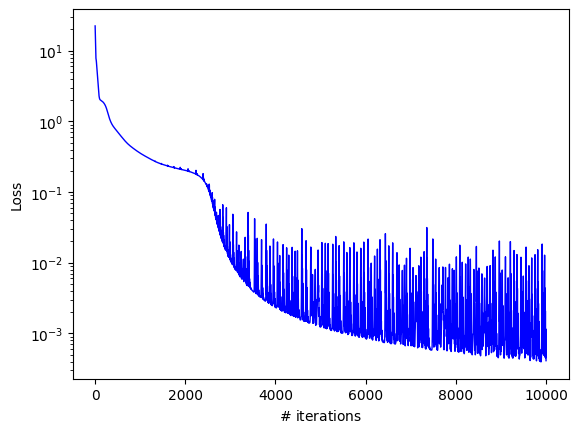

<Figure size 640x480 with 0 Axes>

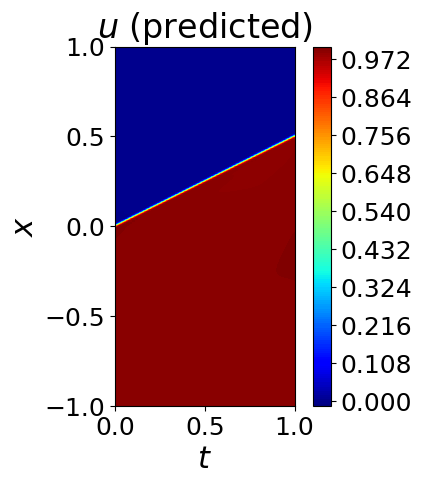

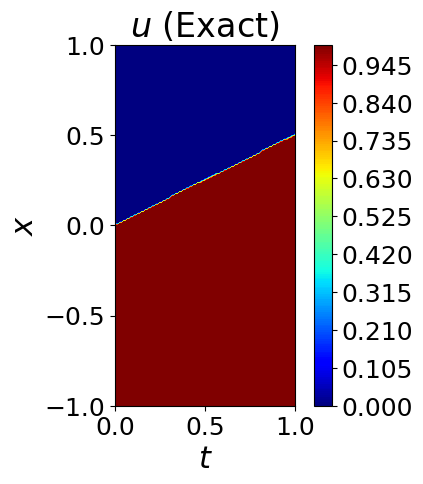

In [12]:
u_pred = vmap_net_u(params_out, X_star[:,0], X_star[:,1])
U_pred = griddata(X_star, u_pred.flatten(), (T, X), method='cubic')

plt.plot(loss_val_his,  'b-', linewidth = 1)
plt.xlabel('$\#$ iterations')
plt.ylabel('Loss')
plt.yscale('log')

fig = plt.figure()
# plt.plot(inv_val_his,  'b-', linewidth = 1)
# plt.xlabel('$\#$ iterations')
# plt.ylabel('Invariants_sum')
# plt.yscale('log')

#ax.legend(frameon=False, loc = 'best')
#ax.set_title('$u(x,y)$', fontsize = 10)
#ax.axis('square')
#savefig('./figures/KdV_IC_MSEhistory')

#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, U_pred, 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
#    ax.set_xlim(0, 1)
#    ax.set_ylim(0, 2)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (predicted)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)
#plt.plot(xx1[:,0:1],xx1[:,1:2], 'kx',markersize=15)
#plt.plot(xx2[:,0:1],xx2[:,1:2], 'rx',markersize=15)
#plt.plot(xx3[:,0:1],xx3[:,1:2], 'gx',markersize=15)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConst')
#%%
#fig, ax = newfig(1.0, 1.1)
fig = plt.figure()
gridspec.GridSpec(1,1)

ax = plt.subplot2grid((1,1), (0,0))
levels = np.linspace(-3.4,3.9, 30)
CS_pred1 = ax.contourf(T, X, np.squeeze(Exact), 200, cmap='jet', origin='lower')
cbar = fig.colorbar(CS_pred1)
cbar.ax.tick_params(labelsize=18)
# ax.set_xlim(0, 1)
# ax.set_ylim(-1, 1)
ax.set_aspect(1)
ax.set_xlabel('$t$', fontsize = 22)
ax.set_ylabel('$x$', fontsize = 22)
ax.set_title('$ u $ (Exact)', fontsize = 24)
ax.tick_params(axis="x", labelsize = 18)
ax.tick_params(axis="y", labelsize = 18)

fig.tight_layout()
fig.set_size_inches(w=4,h=5)
plt.show()
#savefig('./figures/KDV_IntConstEx')

In [13]:
params_out

[Array(0.17794406, dtype=float32),
 (Array([[-0.2754809 , -0.00109755],
         [-0.05803312,  0.07758825],
         [ 0.16230789,  0.14377925],
         [-0.3411114 ,  0.19067396],
         [-0.13486193, -0.02853465],
         [-0.07784236,  0.40266192],
         [ 0.00374931,  0.24145187],
         [ 0.08648764,  0.14674914],
         [ 0.27243188, -0.16378818],
         [-0.1789096 ,  0.21038991],
         [ 0.1269892 , -0.10620226],
         [ 0.0318971 ,  0.16080359],
         [ 0.18436557, -0.16072038],
         [-0.08825842,  0.20297095],
         [-0.24989006, -0.18134132],
         [-0.2954992 ,  0.39068004],
         [ 0.2129243 ,  0.107984  ],
         [-0.04907533,  0.11184461],
         [ 0.24443175,  0.1581542 ],
         [ 0.13140513, -0.28927144],
         [ 0.12114947,  0.11154911],
         [-0.1338827 ,  0.148542  ],
         [ 0.16265701,  0.2485812 ],
         [-0.13587368,  0.02373575],
         [ 0.14108068,  0.11811884],
         [ 0.13390005,  0.06400604],
   